# Auditoría de leakage — Lead Scoring

Respalda la decisión DEC-014. El análisis bivariante marcó `ult_actividad` (IV 0,78) y `ocupacion` (IV 0,94) como posibles fugas de información (IV > 0,5). Este notebook mide cuánto depende el modelo de ellas y qué tan plausible es que reflejen el proceso comercial y no el perfil del lead.

**Alcance**
- Solo se usa el tablón de entrenamiento. `validation.pkl` no se toca.
- Se usa la configuración congelada de DEC-009 (`LogisticRegression`, `C`, `penalty`, `solver`), sin reajustarla por escenario.
- Supuesto de diseño a confirmar: el lead se puntúa durante el seguimiento, con la información acumulada hasta ese momento.

**Limitaciones**
- Una validación aleatoria no detecta leakage: la fuga está presente en train y en validación.
- El dataset no tiene fecha, por lo que no hay validación temporal.
- Las 40 variables se eligieron con RFECV sobre este mismo train y el escalado se ajustó sobre todo train, de modo que el AUC base es algo optimista. Las comparaciones entre escenarios son relativas y comparten esa condición.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score

PROJECT_ROOT = Path.cwd().parent
tablon = pd.read_pickle(PROJECT_ROOT / "02_datos" / "03_Entrenamiento" / "05_train_tablon_preseleccion.pkl")
tablon_eda = pd.read_pickle(PROJECT_ROOT / "02_datos" / "03_Entrenamiento" / "03_train_tablon_eda.pkl")
config = json.loads((PROJECT_ROOT / "06_resultados" / "Modelizacion" / "config_mejor_modelo.json").read_text(encoding="utf-8"))
params = config["parametros"]

assert tablon.index.equals(tablon_eda.index), "El tablón preseleccionado y el EDA deben tener las mismas filas"
y = tablon["compra"]
X = tablon.drop(columns="compra")

ult = [c for c in X if c.startswith("ult_actividad_")]
ocu = [c for c in X if c.startswith("ocupacion_")]
captura = [c for c in X if c.startswith(("origen_", "fuente_", "ambito_", "ocupacion_", "no_enviar_email_"))]

print(f"Filas: {len(X)}; variables: {X.shape[1]}; tasa de compra: {y.mean():.2%}")
print(f"Parámetros congelados (DEC-009): {params}")
print(f"ult_actividad: {len(ult)} dummies | ocupacion: {len(ocu)} dummies | conocidas al captar: {len(captura)}")

Filas: 6360; variables: 40; tasa de compra: 37.48%
Parámetros congelados (DEC-009): {'C': 14.528246637516036, 'penalty': 'l2', 'solver': 'saga', 'max_iter': 5000, 'random_state': 42}
ult_actividad: 7 dummies | ocupacion: 4 dummies | conocidas al captar: 26


## Ablación: cuánto depende el modelo de las variables sospechosas

Se reentrena el mismo modelo quitando o aislando los grupos sospechosos y se compara el ROC AUC. Todos los escenarios usan **los mismos folds** (5 folds × 3 repeticiones, `random_state=42`), por lo que la diferencia contra la línea base es una comparación pareada.

| Escenario | Qué responde |
|---|---|
| A. 40 variables | línea base |
| B. sin `ult_actividad_*` | cuánto depende de la última actividad |
| C. sin `ocupacion_*` | cuánto depende de la ocupación |
| D. sin ambas | dependencia conjunta |
| E. solo ambas | cuánto explican por sí solas |
| F. solo variables conocidas al captar | rendimiento posible si se puntúa en la captura |

Lectura (heurística, no un estándar): una caída de AUC menor a 0,01 es despreciable, entre 0,01 y 0,03 moderada y mayor a 0,03 alta. Una caída alta **no prueba** leakage: puede ser señal legítima. Solo indica cuánto riesgo se asume si la variable resultara ser una fuga.

,escenario,n_variables,AUC_medio,AUC_std,delta_vs_A,delta_std,folds_peores_que_A
0,A. 40 variables,40,0.8947,0.0072,+0.0000,0.0000,0
1,B. sin ult_actividad,33,0.8581,0.0079,-0.0366,0.0063,15
2,C. sin ocupacion,36,0.8799,0.0091,-0.0148,0.0043,15
3,D. sin ambas,29,0.8376,0.0088,-0.0571,0.0059,15
4,E. solo ambas,11,0.7960,0.0092,-0.0987,0.0080,15
5,F. solo conocidas al captar,26,0.7722,0.0109,-0.1225,0.0111,15


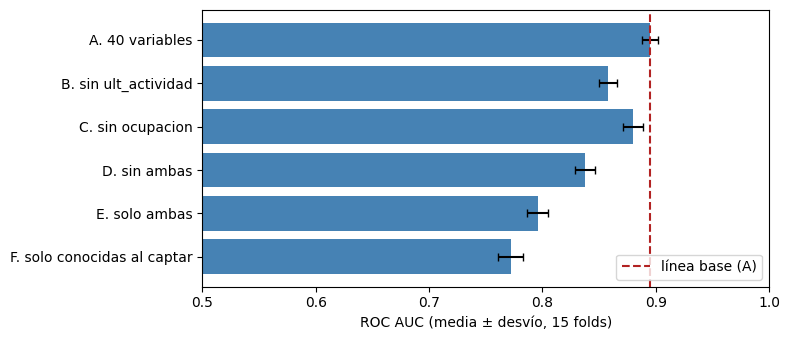

In [2]:
escenarios = {
    "A. 40 variables": list(X.columns),
    "B. sin ult_actividad": [c for c in X if c not in ult],
    "C. sin ocupacion": [c for c in X if c not in ocu],
    "D. sin ambas": [c for c in X if c not in ult + ocu],
    "E. solo ambas": ult + ocu,
    "F. solo conocidas al captar": captura,
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
folds = {nombre: cross_val_score(LogisticRegression(**params), X[cols], y, cv=cv, scoring="roc_auc", n_jobs=-1)
         for nombre, cols in escenarios.items()}

base = folds["A. 40 variables"]
filas = []
for nombre, cols in escenarios.items():
    f = folds[nombre]
    d = f - base
    filas.append({"escenario": nombre, "n_variables": len(cols), "AUC_medio": f.mean(), "AUC_std": f.std(),
                  "delta_vs_A": d.mean(), "delta_std": d.std(ddof=1), "folds_peores_que_A": int((d < 0).sum())})
ablacion = pd.DataFrame(filas)
display(ablacion.style.format({"AUC_medio": "{:.4f}", "AUC_std": "{:.4f}", "delta_vs_A": "{:+.4f}", "delta_std": "{:.4f}"}))

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(ablacion["escenario"], ablacion["AUC_medio"], xerr=ablacion["AUC_std"], color="steelblue", capsize=3)
ax.axvline(ablacion.loc[0, "AUC_medio"], color="firebrick", linestyle="--", label="línea base (A)")
ax.invert_yaxis()
ax.set_xlim(0.5, 1)
ax.set_xlabel("ROC AUC (media ± desvío, 15 folds)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## ¿Reflejan el proceso comercial o el perfil del lead?

Una variable puede tener una tasa de compra alta simplemente porque está asociada con otra (por ejemplo, un canal que concentra compradores). Se recalcula la tasa de compra por categoría **dentro de estratos** de otra variable. Si la diferencia entre categorías persiste en cada estrato, la variable tiene señal propia; si se aplana, era un reflejo de la otra.

Primero, el control por **tiempo en el sitio** (cuartiles de `tiempo_en_site_total`, un indicador de engagement). Las celdas con menos de 20 registros se dejan vacías.

Registros por cuartil de tiempo en el sitio:


,registros
tiempo_cuartil,
"(-0.001, 23.0]",1597
"(23.0, 252.0]",1593
"(252.0, 943.25]",1580
"(943.25, 2272.0]",1590


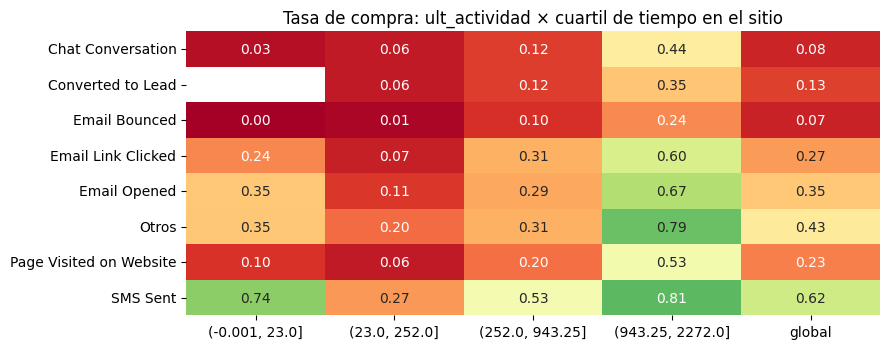

Registros por celda:


tiempo_cuartil,"(-0.001, 23.0]","(23.0, 252.0]","(252.0, 943.25]","(943.25, 2272.0]"
ult_actividad,,,,
Chat Conversation,451,106,74,48
Converted to Lead,11,125,105,49
Email Bounced,36,81,69,33
Email Link Clicked,75,45,39,30
Email Opened,546,612,632,581
Otros,20,87,91,95
Page Visited on Website,29,158,137,111
SMS Sent,429,379,433,643


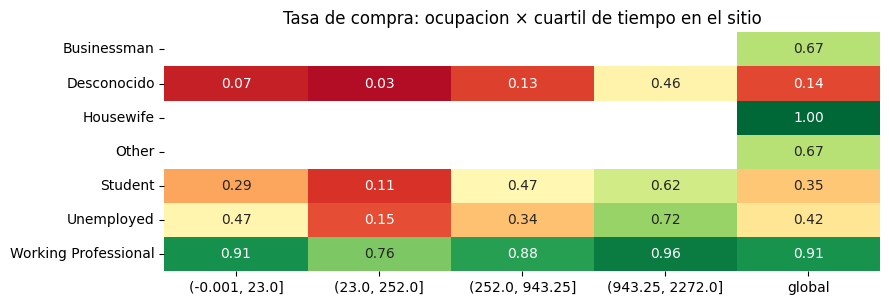

Registros por celda:


tiempo_cuartil,"(-0.001, 23.0]","(23.0, 252.0]","(252.0, 943.25]","(943.25, 2272.0]"
ocupacion,,,,
Businessman,1,2,1,2
Desconocido,626,493,451,314
Housewife,1,1,3,2
Other,0,2,2,5
Student,45,38,40,26
Unemployed,785,1006,964,1043
Working Professional,139,51,119,198


In [3]:
t = tablon_eda.copy()
t["tiempo_cuartil"] = pd.qcut(t["tiempo_en_site_total"], q=4, duplicates="drop")
print("Registros por cuartil de tiempo en el sitio:")
display(t["tiempo_cuartil"].value_counts().sort_index().to_frame("registros"))

def tasa_por_estrato(col, estrato, min_n=20):
    g = t.groupby([col, estrato], observed=True)["compra"].agg(tasa="mean", n="size").reset_index()
    g["tasa"] = g["tasa"].where(g["n"] >= min_n)
    return g.pivot(index=col, columns=estrato, values="tasa"), g.pivot(index=col, columns=estrato, values="n")

def mostrar_estrato(col, estrato, titulo):
    tasas, ns = tasa_por_estrato(col, estrato)
    tasas.columns = tasas.columns.astype(str)
    ns.columns = ns.columns.astype(str)
    tasas["global"] = t.groupby(col)["compra"].mean()
    fig, ax = plt.subplots(figsize=(9, max(2.5, 0.45 * len(tasas))))
    sns.heatmap(tasas, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, cbar=False, ax=ax)
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.tight_layout()
    plt.show()
    print("Registros por celda:")
    display(ns.fillna(0).astype(int))

mostrar_estrato("ult_actividad", "tiempo_cuartil", "Tasa de compra: ult_actividad × cuartil de tiempo en el sitio")
mostrar_estrato("ocupacion", "tiempo_cuartil", "Tasa de compra: ocupacion × cuartil de tiempo en el sitio")

Segundo, el control por **origen del lead**. `Lead Add Form` compra 91% y puede estar concentrando categorías de `ult_actividad` y `ocupacion`. Si es así, parte de su aparente poder predictivo vendría del canal.

Composición de origen dentro de cada categoría (% de filas):


origen,API,Landing Page Submission,Lead Add Form,Lead Import
ult_actividad,,,,
Chat Conversation,90.6,9.0,0.4,0.0
Converted to Lead,38.3,61.7,0.0,0.0
Email Bounced,25.6,70.3,3.7,0.5
Email Link Clicked,47.1,44.4,8.5,0.0
Email Opened,37.7,57.0,4.6,0.8
Otros,19.8,52.9,22.9,4.4
Page Visited on Website,27.8,69.4,2.8,0.0
SMS Sent,30.5,59.5,9.7,0.3


origen,API,Landing Page Submission,Lead Add Form,Lead Import
ocupacion,,,,
Businessman,50.0,33.3,16.7,0.0
Desconocido,53.7,45.9,0.0,0.4
Housewife,14.3,71.4,14.3,0.0
Other,22.2,66.7,11.1,0.0
Student,37.6,53.7,8.7,0.0
Unemployed,34.8,57.9,6.6,0.8
Working Professional,24.5,49.5,25.8,0.2


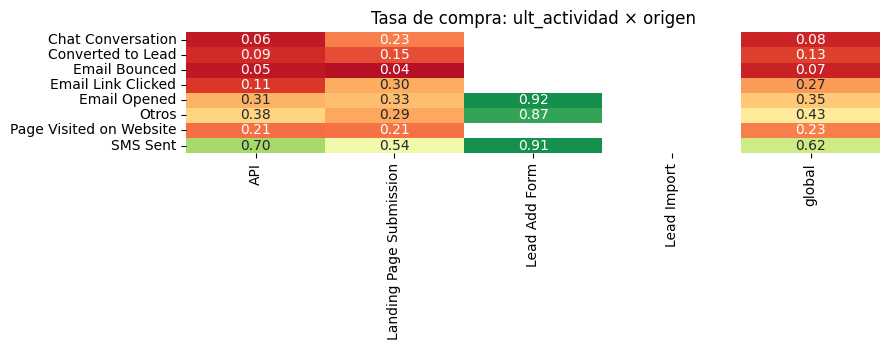

Registros por celda:


origen,API,Landing Page Submission,Lead Add Form,Lead Import
ult_actividad,,,,
Chat Conversation,615,61,3,0
Converted to Lead,111,179,0,0
Email Bounced,56,154,8,1
Email Link Clicked,89,84,16,0
Email Opened,894,1351,108,18
Otros,58,155,67,13
Page Visited on Website,121,302,12,0
SMS Sent,574,1121,183,6


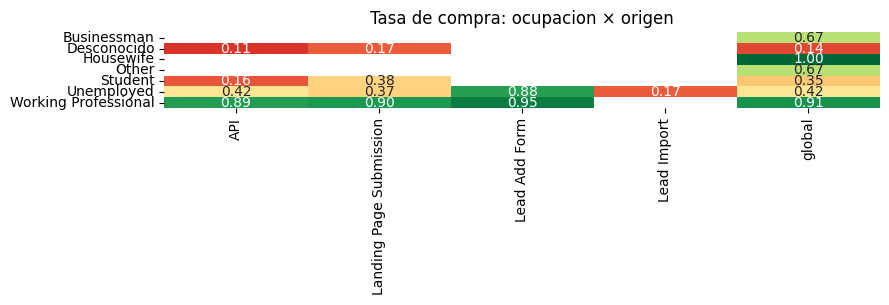

Registros por celda:


origen,API,Landing Page Submission,Lead Add Form,Lead Import
ocupacion,,,,
Businessman,3,2,1,0
Desconocido,1011,865,0,8
Housewife,1,5,1,0
Other,2,6,1,0
Student,56,80,13,0
Unemployed,1321,2198,250,29
Working Professional,124,251,131,1


In [4]:
print("Composición de origen dentro de cada categoría (% de filas):")
for col in ["ult_actividad", "ocupacion"]:
    display((pd.crosstab(t[col], t["origen"], normalize="index") * 100).round(1))

mostrar_estrato("ult_actividad", "origen", "Tasa de compra: ult_actividad × origen")
mostrar_estrato("ocupacion", "origen", "Tasa de compra: ocupacion × origen")

## Conclusiones

**Dependencia del modelo (ablación, 15 folds pareados; en todos los escenarios los 15 folds empeoran respecto de A)**

| Escenario | AUC medio | Δ vs A | Lectura |
|---|---|---|---|
| A. 40 variables | 0,8947 | — | línea base |
| B. sin `ult_actividad` | 0,8581 | -0,037 | dependencia alta |
| C. sin `ocupacion` | 0,8799 | -0,015 | dependencia moderada |
| D. sin ambas | 0,8376 | -0,057 | dependencia alta |
| E. solo ambas | 0,7960 | -0,099 | explican bastante por sí solas |
| F. solo conocidas al captar | 0,7722 | -0,123 | rendimiento sin comportamiento ni scores |

El modelo conserva un AUC de 0,838 sin ninguna de las dos variables, de modo que el resto de las variables (tiempo en el sitio, scores, origen, fuente) aporta una señal sólida. Si ambas resultaran ser una fuga, 0,838 es un piso conservador.

**Controles por engagement y por origen**

- `ult_actividad`: parte de la baja tasa de `Chat Conversation` y `Email Bounced` se explica por composición. `Chat Conversation` pasa de 3% a 44% de compra entre el primer y el último cuartil de tiempo en el sitio, y el 91% de esas filas viene de `API`. `Converted to Lead`, `Page Visited on Website` y `Email Link Clicked` mantienen tasas bajas en ambos orígenes, como corresponde a eventos tempranos del embudo, no a eventos posteriores a la compra.
- `SMS Sent` es la categoría con la señal más difícil de explicar: supera a `Email Opened` en los cuatro cuartiles de tiempo (0,74 / 0,27 / 0,53 / 0,81 contra 0,35 / 0,11 / 0,29 / 0,67) y en `API` (0,70 contra 0,31) y `Landing Page Submission` (0,54 contra 0,33). Es compatible con un seguimiento comercial posterior a la calificación del lead, o incluso al cierre.
- `ocupacion`: la señal es robusta. `Working Professional` compra entre 76% y 96% en cada cuartil de tiempo y 89% a 95% en cada origen, mientras `Desconocido` queda 26 a 40 puntos por debajo de `Unemployed` en cada cuartil. No es un reflejo de engagement ni de origen.
- `Lead Add Form` concentra compra de ~90% sin importar la última actividad u ocupación, y ningún `Desconocido` proviene de ese origen: es un canal que siempre captura el perfil.

**Qué puede y qué no puede afirmarse**

- Los controles descartan que `ocupacion` y `SMS Sent` sean un simple reflejo de engagement u origen. **No pueden** distinguir entre señal legítima y fuga de información: ambas persisten bajo los mismos controles. Con un dataset sin fecha ni negocio, esa distinción solo puede resolverse con el supuesto de momento de scoring.
- `ocupacion`: declarada por el lead y con efecto robusto; riesgo de leakage bajo a moderado y dependencia moderada.
- `ult_actividad`: se actualiza con cada evento y su categoría más fuerte (`SMS Sent`) es compatible con un evento posterior a la calificación; riesgo más alto y dependencia alta.

**Limitaciones**

- Se usó `C` fijo de DEC-009 en todos los escenarios, sin reajustarlo.
- Los umbrales de lectura (0,01 y 0,03 de AUC) son heurísticos.
- El AUC base es algo optimista: RFECV y el escalado se ajustaron sobre todo train. La comparación entre escenarios comparte esa condición.
- El tiempo en el sitio no es monótono con la compra (el primer cuartil, que incluye leads con 0 segundos, compra más que el segundo). No se investigó esa población.